# 3. A chuva aumenta os chamados?

O Recife tem uma estação chuvosa bem marcada, de abril a agosto, e chuva forte entope galerias, alaga ruas e derruba árvores. Se a chuva antecipa picos de chamados, a Emlurb pode reforçar as equipes de drenagem e de poda a partir da previsão do tempo, em vez de reagir à fila.

Hipótese H3: nos dias de chuva forte, os chamados de drenagem ficam acima do normal para aquele mês e dia da semana.

A chuva vem do Open-Meteo (API histórica, ver `src/ingestion/weather.py`) e está na tabela `daily_weather`, ligada aos chamados pela data de abertura.

In [1]:
import pandas as pd
from scipy import stats
from sqlalchemy import text

from src.analysis.charts import plot_rain_and_tickets
from src.analysis.weather_effect import pivot_daily, rainy_day_effect
from src.config import DOCS_DIR, SQL_DIR
from src.db.load import get_engine

GROUPS = ["DRENAGEM", "ARBORIZACAO", "ILUMINACAO PUBLICA", "LIMPEZA URBANA"]

# Tickets opened per day and group next to that day's rain, days without tickets as zero
sql = (SQL_DIR / "analyses" / "09_daily_tickets_and_rain.sql").read_text(encoding="utf-8")
with get_engine().connect() as connection:
    daily = pivot_daily(pd.read_sql(text(sql), connection), GROUPS)
daily.drop(columns="day").describe().loc[["mean", "50%", "max"]].round(1)

group_name,rain_mm,DRENAGEM,ARBORIZACAO,ILUMINACAO PUBLICA,LIMPEZA URBANA
mean,3.7,24.6,30.4,128.7,55.4
50%,2.3,25.0,29.0,141.0,52.0
max,63.2,86.0,209.0,368.0,217.0


Um cuidado antes de tudo: o Open-Meteo estima a chuva a partir de um modelo em grade, não de um pluviômetro. Em 2024 ele soma cerca de 1.230 mm, bem abaixo da média histórica do Recife, que passa de 2.000 mm por ano, e suaviza os temporais. O dado serve para dizer quais dias choveram mais que outros, não quantos milímetros caíram. Por isso a análise usa faixas relativas (os dias mais chuvosos do período), e não limites fixos em mm.

## Primeira impressão: os meses chuvosos são os de mais chamados de drenagem?

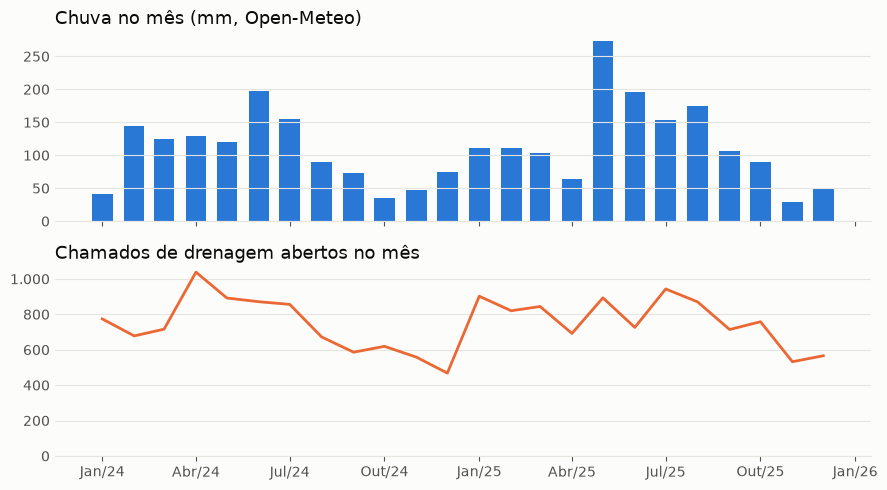

In [2]:
monthly = daily.set_index("day").resample("MS")[["rain_mm", "DRENAGEM"]].sum()
plot_rain_and_tickets(monthly, DOCS_DIR / "img" / "rain_vs_drainage.png")

No mês a relação é fraca: maio de 2025 foi o mês mais chuvoso (273 mm) sem ser o de mais chamados, e abril de 2024 teve o pico de drenagem com chuva moderada. Mês é uma escala grossa demais, porque um temporal de dois dias some no total do mês.

In [3]:
weekly = daily.set_index("day").resample("W").sum(numeric_only=True)
correlations = {group: tuple(stats.spearmanr(weekly["rain_mm"], weekly[group])) for group in GROUPS}
pd.DataFrame(correlations, index=["spearman_rho", "p_value"]).T.round(3)

,spearman_rho,p_value
DRENAGEM,0.441,0.000
ARBORIZACAO,0.406,0.000
ILUMINACAO PUBLICA,0.394,0.000
LIMPEZA URBANA,-0.028,0.775


Por semana a relação aparece: semanas mais chuvosas têm mais chamados de drenagem, arborização e iluminação (correlação de Spearman perto de 0,4), e nenhuma relação com limpeza urbana, que serve de comparação. Só que semanas chuvosas se concentram na estação chuvosa, quando outras coisas também mudam, então essa correlação ainda não isola o efeito da chuva.

## O teste: dias chuvosos contra o normal do mesmo mês e dia da semana

Para separar a chuva da estação do ano e da queda de fim de semana, cada dia é comparado com a média do mesmo dia da semana no mesmo mês. Um dia conta como chuvoso quando a chuva dele e dos dois dias anteriores está entre os 10% maiores do período, porque muitos pedidos chegam no dia seguinte ao temporal. A diferença entre dias chuvosos e os demais é testada com Mann-Whitney, que não supõe distribuição normal. O cálculo fica em [`src/analysis/weather_effect.py`](../src/analysis/weather_effect.py), o mesmo usado pelo painel estratégico do dashboard.

In [4]:
effect, threshold, rainy_days = rainy_day_effect(daily, GROUPS)
print(f"{rainy_days} dias chuvosos: 3 dias somando pelo menos {threshold:.0f} mm")
effect.round(3)

75 dias chuvosos: 3 dias somando pelo menos 23 mm


,rainy_days_vs_normal_pct,other_days_vs_normal_pct,p_value
group,,,
DRENAGEM,12.970,-1.483,0.008
ARBORIZACAO,19.526,-2.232,0.000
ILUMINACAO PUBLICA,7.163,-0.819,0.003
LIMPEZA URBANA,-6.297,0.720,0.958


Nos 75 dias chuvosos, drenagem ficou 13% acima do normal daquele mês e dia da semana, contra 1,5% abaixo nos demais dias (p = 0,008). O efeito é maior em arborização (+20%, p < 0,001) e menor, mas presente, em iluminação (+7%, p = 0,003). Limpeza urbana fica 6% abaixo do normal em dias chuvosos e não passa no teste, o que mostra que o método não encontra efeito em qualquer grupo.

## Conclusão

H3 confirmada, com efeito moderado. Chuva forte acumulada em três dias deixa os chamados de drenagem cerca de 13% acima do normal e os de arborização cerca de 20%, o que dá poucos chamados a mais por dia (em torno de 3 em drenagem e 6 em arborização). Para a gestão, a previsão do tempo é um bom gatilho para reforçar drenagem e poda nos dias seguintes a temporais. Mas a fila grande de drenagem não vem dos temporais, e sim da velocidade com que ela anda (notebook 02).

Limitações:

- a chuva é estimada por um modelo em grade, que subestima volumes e suaviza temporais; dados de pluviômetro (INMET ou APAC) dariam um teste mais forte;
- um único ponto representa a cidade inteira, e a chuva no Recife varia bastante entre bairros;
- dois anos dão 75 dias chuvosos; o resultado é estatisticamente claro, mas o tamanho do efeito pode mudar com uma série maior.